In [13]:
import pandas as pd
import math
from collections import Counter
from nltk.util import bigrams, trigrams, ngrams

In [14]:
df = pd.read_csv("../pertemuan-03/scrape_kompas_clean.csv")
text_column = "processed_text"  # gunakan hasil preprocessing

# Hapus nilai kosong
df = df.dropna(subset=[text_column])

print(f"Jumlah dokumen: {len(df)}")

Jumlah dokumen: 5


In [15]:
all_text = " ".join(df[text_column].astype(str))
tokens = all_text.split()

print(f"Total token: {len(tokens)}")
print(f"Contoh token: {tokens[:20]}")

Total token: 35
Contoh token: ['deret', 'aktor', 'peran', 'spiderman', 'aktor', 'ryotaro', 'shimizu', 'temu', 'tinggal', 'dunia', 'diam', 'aktor', 'marvelous', 'mrs', 'maisel', 'josh', 'grisetti', 'tinggal', 'dunia', 'aktor']


In [16]:
unigram = Counter(tokens)

print("20 Kata Paling Sering Muncul:")
for word, count in unigram.most_common(20):
    print(f"  {word:<20} : {count}")

20 Kata Paling Sering Muncul:
  aktor                : 5
  tinggal              : 4
  dunia                : 3
  temu                 : 2
  deret                : 1
  peran                : 1
  spiderman            : 1
  ryotaro              : 1
  shimizu              : 1
  diam                 : 1
  marvelous            : 1
  mrs                  : 1
  maisel               : 1
  josh                 : 1
  grisetti             : 1
  bittersweet          : 1
  destiny              : 1
  wang                 : 1
  kai                  : 1
  rumah                : 1


In [17]:
total_tokens = sum(unigram.values())

unigram_probability = {
    word: count / total_tokens
    for word, count in unigram.items()
}

print("\n10 Kata dengan Probabilitas Tertinggi:")
sorted_prob = sorted(
    unigram_probability.items(),
    key=lambda x: x[1],
    reverse=True
)
for word, prob in sorted_prob[:10]:
    print(f"  {word:<20} : {prob:.6f}")


10 Kata dengan Probabilitas Tertinggi:
  aktor                : 0.142857
  tinggal              : 0.114286
  dunia                : 0.085714
  temu                 : 0.057143
  deret                : 0.028571
  peran                : 0.028571
  spiderman            : 0.028571
  ryotaro              : 0.028571
  shimizu              : 0.028571
  diam                 : 0.028571


In [18]:
bigram_tokens = list(bigrams(tokens))
bigram_frequency = Counter(bigram_tokens)

print("20 Bigram Paling Sering Muncul:")
for bigram, count in bigram_frequency.most_common(20):
    print(f"  {' '.join(bigram):<30} : {count}")

20 Bigram Paling Sering Muncul:
  tinggal dunia                  : 3
  temu tinggal                   : 2
  deret aktor                    : 1
  aktor peran                    : 1
  peran spiderman                : 1
  spiderman aktor                : 1
  aktor ryotaro                  : 1
  ryotaro shimizu                : 1
  shimizu temu                   : 1
  dunia diam                     : 1
  diam aktor                     : 1
  aktor marvelous                : 1
  marvelous mrs                  : 1
  mrs maisel                     : 1
  maisel josh                    : 1
  josh grisetti                  : 1
  grisetti tinggal               : 1
  dunia aktor                    : 1
  aktor bittersweet              : 1
  bittersweet destiny            : 1


In [19]:
trigram_tokens = list(trigrams(tokens))
trigram_frequency = Counter(trigram_tokens)

print("20 Trigram Paling Sering Muncul:")
for trigram, count in trigram_frequency.most_common(20):
    print(f"  {' '.join(trigram):<40} : {count}")

20 Trigram Paling Sering Muncul:
  temu tinggal dunia                       : 2
  deret aktor peran                        : 1
  aktor peran spiderman                    : 1
  peran spiderman aktor                    : 1
  spiderman aktor ryotaro                  : 1
  aktor ryotaro shimizu                    : 1
  ryotaro shimizu temu                     : 1
  shimizu temu tinggal                     : 1
  tinggal dunia diam                       : 1
  dunia diam aktor                         : 1
  diam aktor marvelous                     : 1
  aktor marvelous mrs                      : 1
  marvelous mrs maisel                     : 1
  mrs maisel josh                          : 1
  maisel josh grisetti                     : 1
  josh grisetti tinggal                    : 1
  grisetti tinggal dunia                   : 1
  tinggal dunia aktor                      : 1
  dunia aktor bittersweet                  : 1
  aktor bittersweet destiny                : 1


In [20]:
def bigram_probability(word1, word2):
    numerator = bigram_frequency[(word1, word2)]
    denominator = unigram[word1]

    if denominator == 0:
        return 0.0

    return numerator / denominator

# Contoh
word1, word2 = "belajar", "nlp"
prob = bigram_probability(word1, word2)
print(f"P({word2} | {word1}) = {prob:.6f}")

P(nlp | belajar) = 0.000000


In [21]:
def sentence_probability(sentence):
    words = sentence.lower().split()
    probability = 1.0

    for i in range(len(words) - 1):
        p = bigram_probability(words[i], words[i + 1])
        probability *= p

    return probability

# Uji
test_sentences = [
    "saya belajar nlp",
    "nlp menarik sekali",
    "model bahasa sederhana",
]

for sentence in test_sentences:
    p = sentence_probability(sentence)
    print(f"P('{sentence}') = {p:.8f}")

P('saya belajar nlp') = 0.00000000
P('nlp menarik sekali') = 0.00000000
P('model bahasa sederhana') = 0.00000000


In [22]:
vocab_size = len(unigram)

def smoothed_bigram_probability(word1, word2):
    numerator = bigram_frequency[(word1, word2)] + 1
    denominator = unigram[word1] + vocab_size
    return numerator / denominator

# Uji dengan kata yang mungkin tidak ada dalam corpus
word1, word2 = "deep", "learning"
prob = smoothed_bigram_probability(word1, word2)
print(f"Smoothed P({word2} | {word1}) = {prob:.8f}")

Smoothed P(learning | deep) = 0.04000000


In [23]:
def predict_next_word(context_word, top_n=5):
    candidates = []

    for (word1, word2), count in bigram_frequency.items():
        if word1 == context_word:
            p = smoothed_bigram_probability(word1, word2)
            candidates.append((word2, p))

    candidates.sort(key=lambda x: x[1], reverse=True)
    return candidates[:top_n]

# Contoh
context = "belajar"
predictions = predict_next_word(context)
print(f"\nPrediksi kata setelah '{context}':")
for word, prob in predictions:
    print(f"  {word:<20} : {prob:.6f}")


Prediksi kata setelah 'belajar':


In [24]:
def perplexity(probability, N):
    if probability == 0 or probability is None:
        return float("inf")
    return probability ** (-1 / N)

# Contoh
sentence = "saya belajar nlp"
words = sentence.split()
prob = sentence_probability(sentence)
N = len(words)

pp = perplexity(prob, N)
print(f"Kalimat : '{sentence}'")
print(f"P(W)    : {prob:.8f}")
print(f"N       : {N}")
print(f"PP(W)   : {pp:.4f}")

Kalimat : 'saya belajar nlp'
P(W)    : 0.00000000
N       : 3
PP(W)   : inf


In [25]:
print("=" * 60)
print("PERBANDINGAN MODEL N-GRAM")
print("=" * 60)
print(f"Ukuran Vocabulary     : {len(unigram):,}")
print(f"Jumlah Token          : {len(tokens):,}")
print(f"Jumlah Unigram unik   : {len(unigram):,}")
print(f"Jumlah Bigram unik    : {len(bigram_frequency):,}")
print(f"Jumlah Trigram unik   : {len(trigram_frequency):,}")
print()

# Cek sparsity
max_bigram = len(unigram) ** 2
max_trigram = len(unigram) ** 3
print(f"Kemungkinan Bigram maks  : {max_bigram:,}")
print(f"Bigram yang ada          : {len(bigram_frequency):,}")
print(f"Bigram coverage          : {len(bigram_frequency)/max_bigram*100:.4f}%")

PERBANDINGAN MODEL N-GRAM
Ukuran Vocabulary     : 25
Jumlah Token          : 35
Jumlah Unigram unik   : 25
Jumlah Bigram unik    : 31
Jumlah Trigram unik   : 32

Kemungkinan Bigram maks  : 625
Bigram yang ada          : 31
Bigram coverage          : 4.9600%


In [28]:
!pip install matplotlib

  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl (9.5 MB)
Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl (240 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   -------- ------------------------------- 0.5/2.5 MB 2.0 MB/s eta 0:00:01
   ------------ --------------------------- 0.8/2.5 MB 1.6 MB/s eta 0:00:02
   ---------------- ----------------------- 1.0/2.5 MB 1.6 MB/s eta 0:00:01
   ------------------

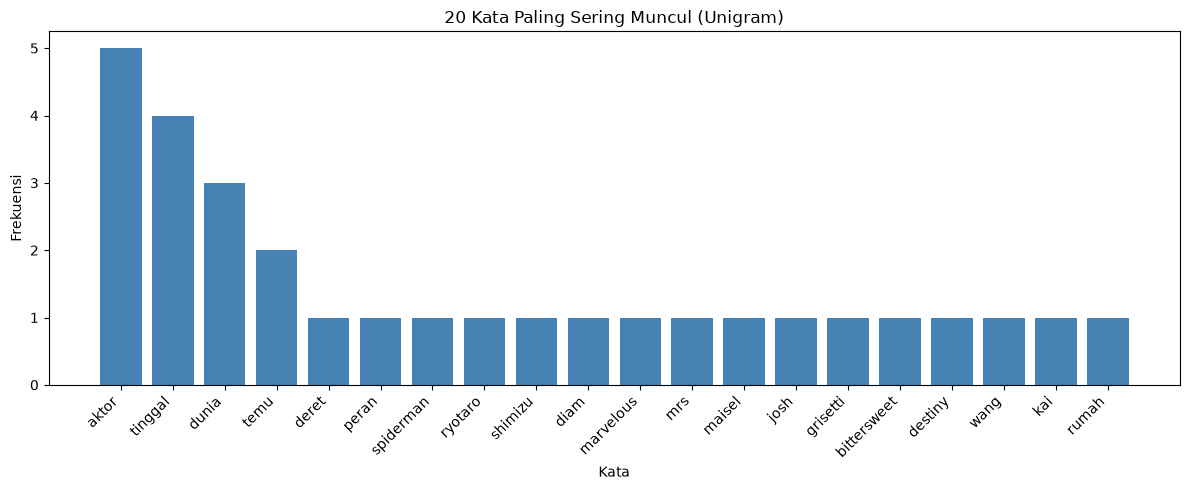

In [29]:
import matplotlib.pyplot as plt

# Top 20 unigram
top_words = unigram.most_common(20)
words_list = [w[0] for w in top_words]
counts_list = [w[1] for w in top_words]

plt.figure(figsize=(12, 5))
plt.bar(words_list, counts_list, color="steelblue")
plt.xticks(rotation=45, ha="right")
plt.xlabel("Kata")
plt.ylabel("Frekuensi")
plt.title("20 Kata Paling Sering Muncul (Unigram)")
plt.tight_layout()
plt.show()